# 4. Wind, eddy energy and isopycnal slope (Sect. 3.3, Fig. 4)

Companion notebook of **Martí-Solana et al., "Observational constraints on eddy saturation in the Antarctic Circumpolar Current"** (State of the Planet, Ocean State Report 11).

This notebook covers the relation of KE, EKE and the cross-stream slope of the σ₀ = 27.3 kg m⁻³ isopycnal (Roemmich–Gilson Argo fields) with the eastward wind stress: trends, lagged correlations and the power-law exponents.

It runs from the processed outputs in `outputs/` only (no raw data, no download), in about one minute. Every figure is drawn by its script in `figures/`; the cells before each figure load the tables behind it and print the values quoted in the paper. The scripts that produced each table from the raw data are named in the text and listed in the README.

In [1]:
from pathlib import Path
import io, os, subprocess, sys, tempfile
import numpy as np, pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src" / "osr11").is_dir() else ROOT.parent      # works from the repository root or from notebooks/
OUT = ROOT / "outputs"                                                 # processed outputs distributed with the repository
FIGDIR = Path(tempfile.mkdtemp(prefix="osr11_nb_"))                    # figures are re-rendered here, not into rendered/
pd.set_option("display.float_format", lambda v: f"{v:.3g}")


def render(script, width=1700):
    """Run one script of figures/ on outputs/ and show the figure it writes (PNG, 600 dpi, reduced here for display)."""
    args = [str(OUT), str(FIGDIR)] if script.startswith("figS") else [str(FIGDIR)]
    r = subprocess.run([sys.executable, str(ROOT / "figures" / script), *args], capture_output=True, text=True,
                       env=dict(os.environ, MPLBACKEND="Agg"))
    assert r.returncode == 0, r.stderr[-3000:]
    png = max((FIGDIR / "png").glob("*.png"), key=lambda p: p.stat().st_mtime)
    from PIL import Image as PILImage
    im = PILImage.open(png).convert("RGB"); im.thumbnail((width, 3 * width)); buf = io.BytesIO(); im.save(buf, "JPEG", quality=88)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(png.name, "written to", FIGDIR / "png")


def ci(row, s="slope", lo="lo", hi="hi", p="p", unit=""):
    pv = "p ≤ 0.003" if row[p] < 0.0034 else f"p = {row[p]:.2g}"          # 300 surrogates: the smallest attainable p is 1/301
    return f"{row[s]:+.1f} [{row[lo]:+.1f}, {row[hi]:+.1f}] {unit}, {pv}"


## Domain means and their trends

Monthly means over the ACC band extended by 100 km (`scripts/04_wind_argo/04g_common_cells.py`), 2004–2025, in % of the mean per decade.

In [2]:
S = pd.read_csv(OUT / "f4e" / "f4e_series.csv"); R = pd.read_csv(OUT / "f4e" / "f4e_results.csv")
d1 = R[R.test == "D1"].set_index("series")
for k in ("wind", "KE", "EKE", "slope"):
    print(f"{k:5s}:", ci(d1.loc[k], s="pct", lo="pct_lo", hi="pct_hi", unit="% per decade"))
M = pd.read_csv(OUT / "f4m" / "f4m_results.csv")
M[M.series.str.contains("monthly test")][["series", "pct", "pct_lo", "pct_hi", "p"]].round(3)

wind : +2.4 [-0.8, +5.5] % per decade, p = 0.15
KE   : +5.2 [+3.0, +7.5] % per decade, p ≤ 0.003
EKE  : +8.9 [+3.3, +14.5] % per decade, p = 0.017
slope: +1.2 [+0.3, +2.0] % per decade, p = 0.02


,series,pct,pct_lo,pct_hi,p
0,"27.3 signed, domain, monthly test",1.17,0.306,2.04,0.02
3,"27.3 signed, Atlantic, monthly test",2.23,0.822,3.64,0.013
4,"27.3 signed, Indian, monthly test",0.235,-0.651,1.12,0.575
5,"27.3 signed, Pacific, monthly test",1.5,-1.19,4.2,0.239


In [3]:
import xarray as xr
m = xr.open_dataset(OUT / "f4m" / "f4m_map.nc"); f = m.slope_fdr.values > 0
print(f"cells of the slope-trend map passing the 10 % false-discovery-rate control: {int(f.sum())}; of them with a positive trend: {int((m.slope_pct.values[f] > 0).sum())}")

cells of the slope-trend map passing the 10 % false-discovery-rate control: 13; of them with a positive trend: 13


## Lagged correlation with the wind (Fig. 4e)

Each series deseasonalised, detrended and smoothed with a 12-month running mean; wind leading by 0–36 months; p-values from 2000 phase-randomised wind surrogates, at each lag (`p_pt_max`) and allowing for the search over the 37 lags (`p_fw`). Script: `04k_lag_correlation.py`.

In [4]:
pd.read_csv(OUT / "x12" / "x12_summary.csv")[["series", "lag_max", "r_max", "p_pt_max", "p_fw", "lag_max_lo", "lag_max_hi", "sig_lags"]]

,series,lag_max,r_max,p_pt_max,p_fw,lag_max_lo,lag_max_hi,sig_lags
0,KE,9,0.569,0.002,0.009,5,19,"4,5,6,7,8,9,10,11,12,13,14"
1,EKE,11,0.474,0.019,0.113,8,23,"8,9,10,11,12,13,14"
2,slope,19,0.181,0.423,0.921,6,36,NaN


## Power-law exponents (Fig. 4d)

Exponent *b* of X ∝ τᵇ: least-squares slope of ln X (annual means, 2004–2025) on ln τ of the previous year, with the trends retained and with both series detrended (`04i_wind_exponents.py`); 95 % intervals from simulations of the fitted model (`04j_exponent_intervals.py`).

In [5]:
b = pd.read_csv(OUT / "x10" / "x10_intervals.csv").set_index("series"); p = pd.read_csv(OUT / "x9" / "x9_sensitivity_log.csv").set_index("series")
tab = b[["b", "b_lo", "b_hi", "b_detr", "bd_lo", "bd_hi"]].assign(p=p.p, shared_trend_fraction=p.shared_trend_frac)
tab.round(2)

,b,b_lo,b_hi,b_detr,bd_lo,bd_hi,p,shared_trend_fraction
series,,,,,,,,
KE,0.5,0.11,0.89,0.29,0.14,0.44,0.01,0.41
EKE,0.9,0.18,1.61,0.55,0.23,0.89,0.01,0.39
slope,0.09,-0.03,0.2,0.04,-0.03,0.11,0.17,0.55


The cell below recomputes the exponents from the monthly series, to show the calculation.

In [6]:
yrs = np.arange(2001, 2026); ann = lambda c: np.array([S[c][S.year == y].mean() for y in yrs])
lw = np.log(ann("wind")); wx = lw[(yrs >= 2003) & (yrs <= 2024)]            # wind of the previous year
for k in ("KE", "EKE", "slope"):
    y = np.log(ann(k))[yrs >= 2004]; t = np.arange(y.size)
    detr = lambda v: v - np.polyval(np.polyfit(t, v, 1), t)
    print(f"{k:5s}: b = {np.polyfit(wx, y, 1)[0]:.2f}; both detrended: {np.polyfit(detr(wx), detr(y), 1)[0]:.2f}")

KE   : b = 0.50; both detrended: 0.29
EKE  : b = 0.90; both detrended: 0.55
slope: b = 0.09; both detrended: 0.04


## Width of the extension of the band

The same diagnostics with the band alone and with extensions of 200 and 300 km (`04m_buffer_width.py`).

In [7]:
X = pd.read_csv(OUT / "x14" / "x14_results.csv")
t = X[X.test == "trend 2004-2025"].pivot(index="series", columns="domain", values="pct").round(1)
e = X[X.test == "exponent 2004-2025"].pivot(index="series", columns="domain", values="b").round(2)
print("trend, % per decade"); display(t); print("exponent b"); display(e)

trend, % per decade


domain,band,buf100,buf200,buf300
series,,,,
EKE,9.2,8.9,8.5,8.2
KE,5.5,5.2,5.1,4.9
slope,1.1,1.2,1,1
wind,2.5,2.4,2.1,2


exponent b


domain,band,buf100,buf200,buf300
series,,,,
EKE,0.83,0.9,0.93,0.95
KE,0.48,0.5,0.49,0.5
slope,0.09,0.09,0.08,0.07


## Figure 4

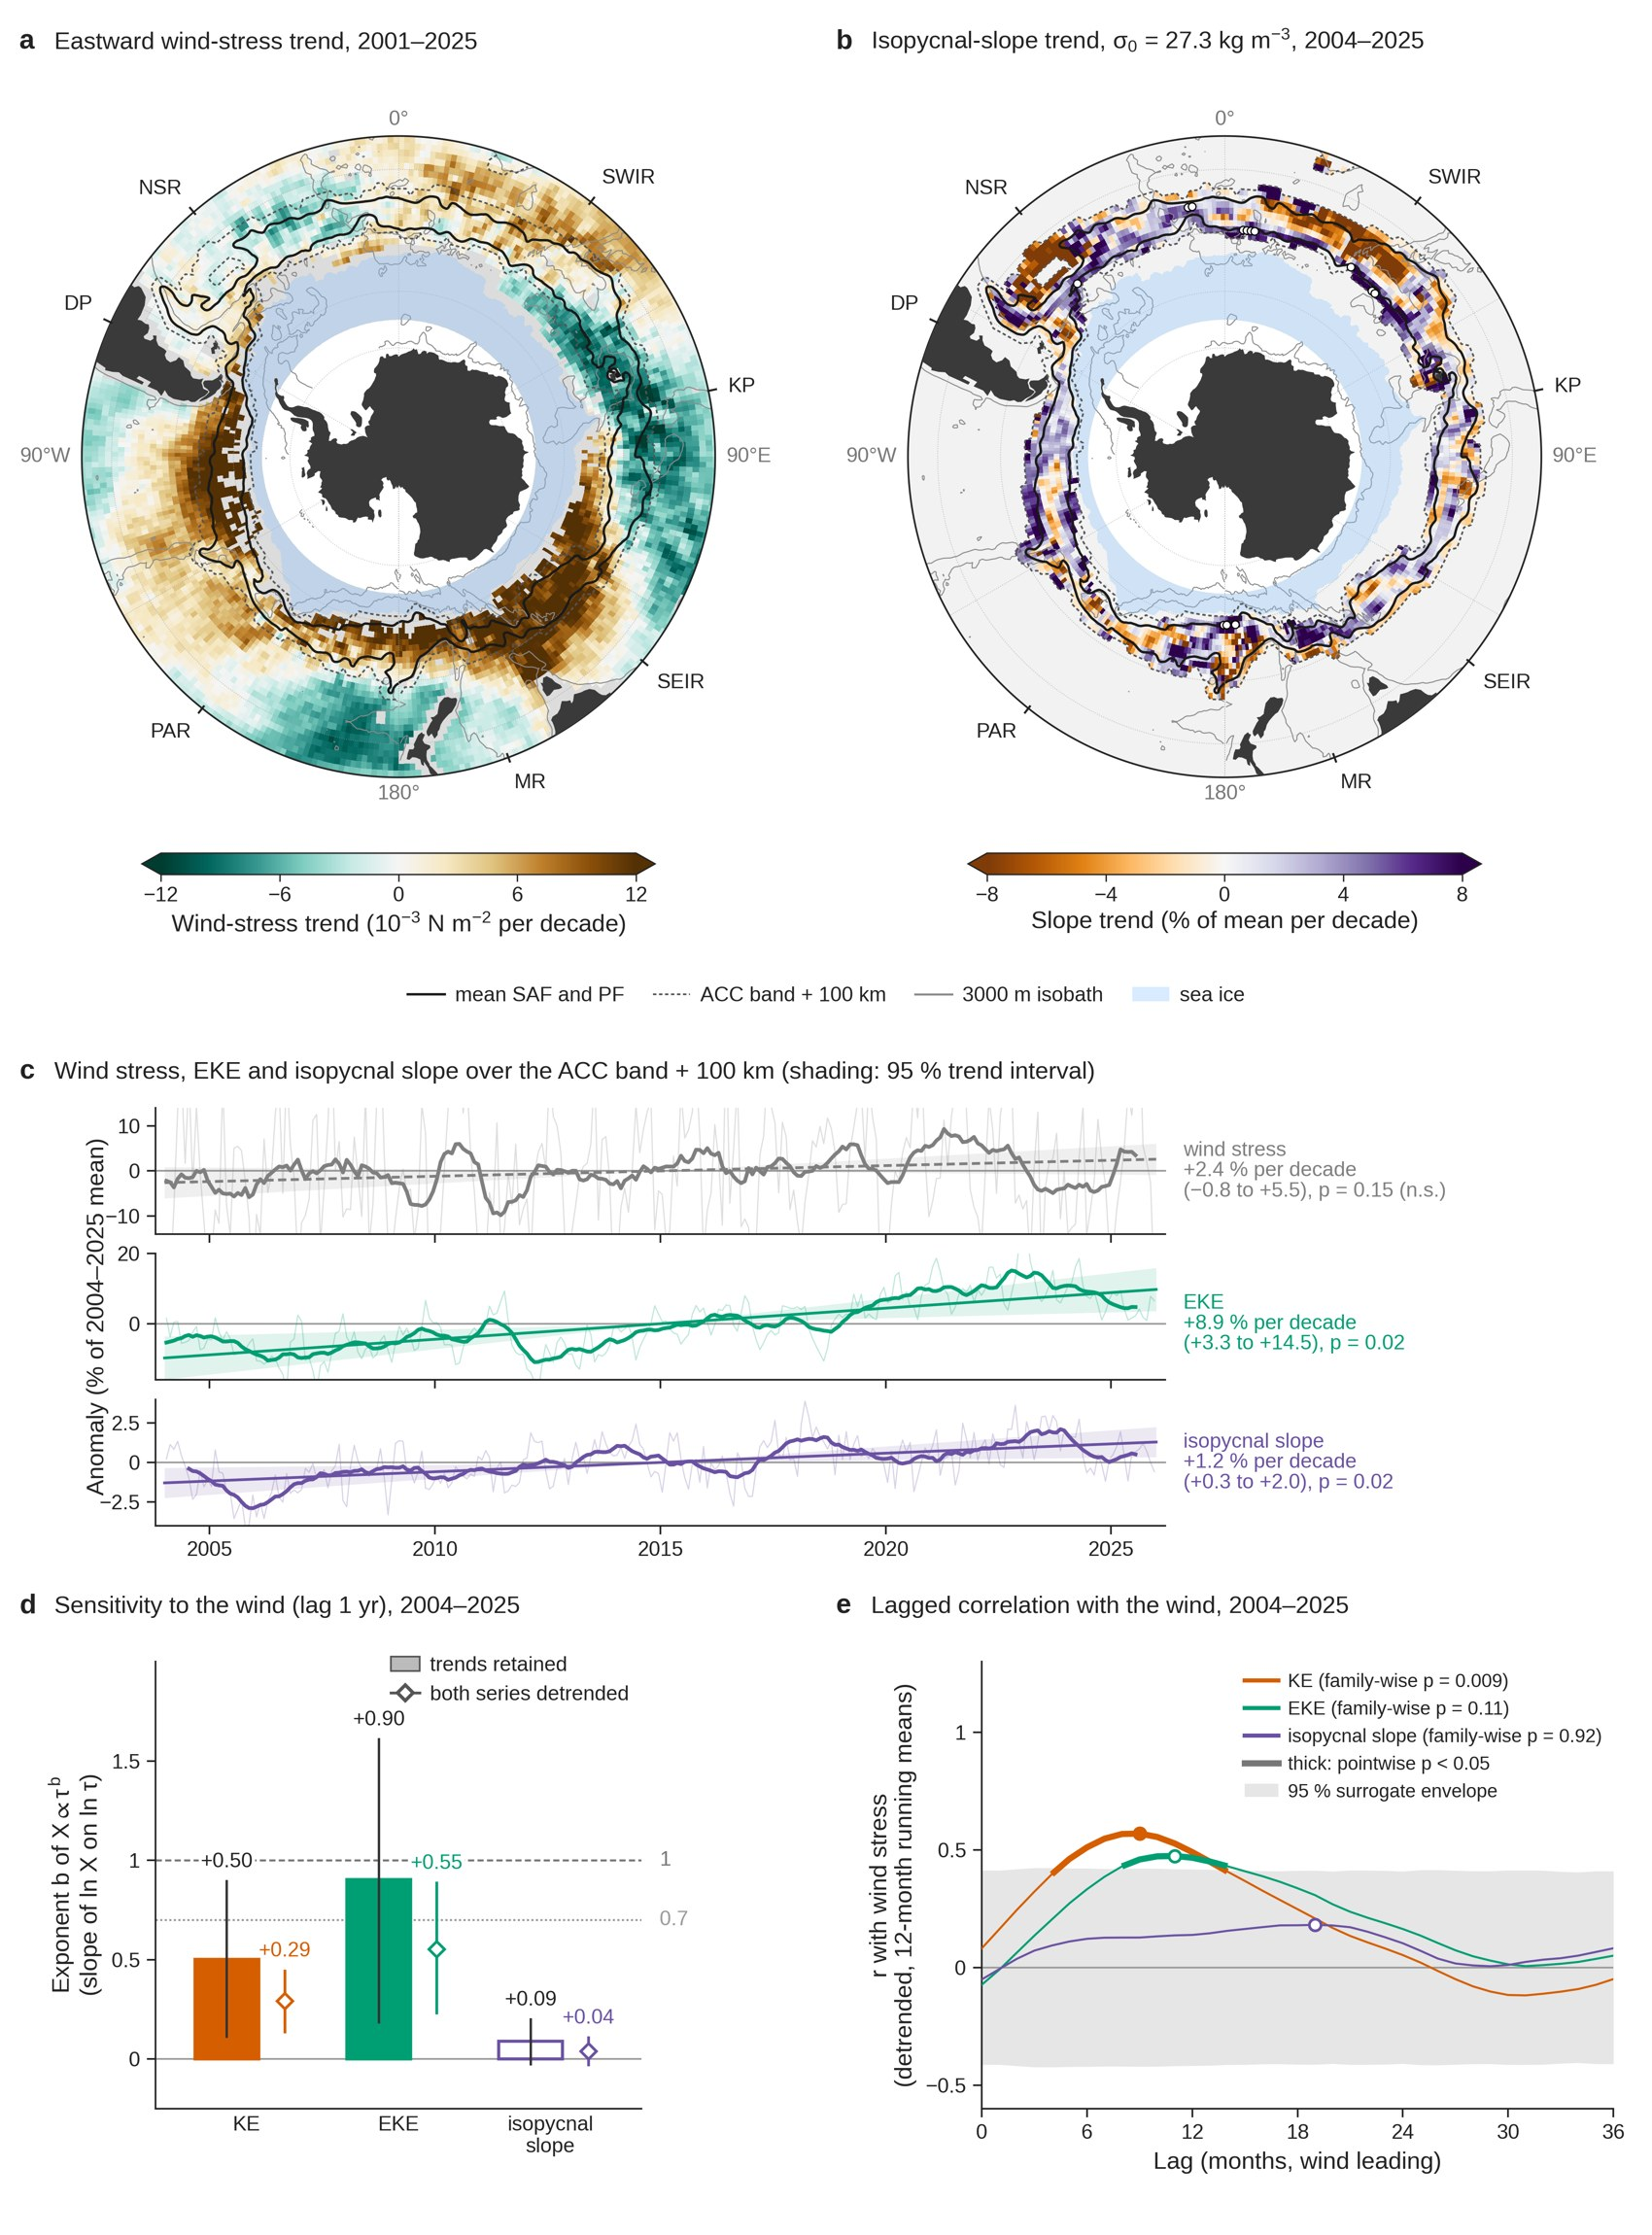

Figure4.png written to /tmp/osr11_nb_88eqncsr/png


In [8]:
render("fig4_wind_slope.py")